# Zadání 4 - Výpočet impulsní funkce pomocí korelační analýzy


## Načtení dat náhodného signálu z úlohy 1 a vizualizace


Počet vzorků náhodného signálu z úlohy 1: N = 251
Perioda vzorkování: T0 = 1.0 s


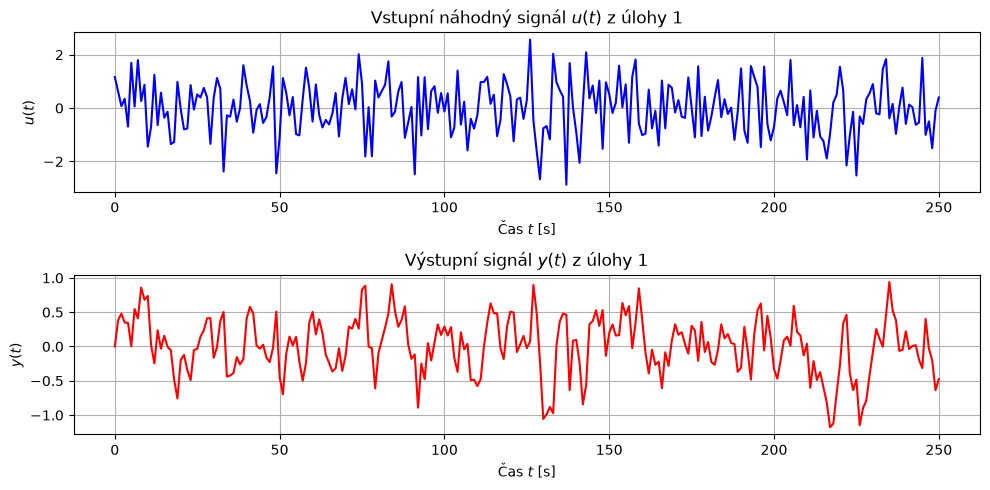

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, linalg

u_rnd = pd.read_csv('u.csv', header=None).values.flatten()
y_rnd = pd.read_csv('y.csv', header=None).values.flatten()

N_rnd = len(u_rnd)
T0_rnd = 1.0
t_rnd = np.arange(N_rnd) * T0_rnd

print(f"Počet vzorků náhodného signálu z úlohy 1: N = {N_rnd}")
print(f"Perioda vzorkování: T0 = {T0_rnd:.1f} s")

plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1)
plt.plot(t_rnd, u_rnd, 'b')
plt.title(r'Vstupní náhodný signál $u(t)$ z úlohy 1')
plt.xlabel(r'Čas $t\ [\mathrm{s}]$')
plt.ylabel(r'$u(t)$')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t_rnd, y_rnd, 'r')
plt.title(r'Výstupní signál $y(t)$ z úlohy 1')
plt.xlabel(r'Čas $t\ [\mathrm{s}]$')
plt.ylabel(r'$y(t)$')
plt.grid(True)
plt.tight_layout()
plt.savefig("data_nahodny.png", dpi=300)
plt.show()


## Načtení dat PNBS z úlohy 3 a vizualizace


Počet vzorků dat PNBS z úlohy 3: N = 315 (5 period po 63 vzorcích)
Perioda vzorkování: T0 = 0.5 s


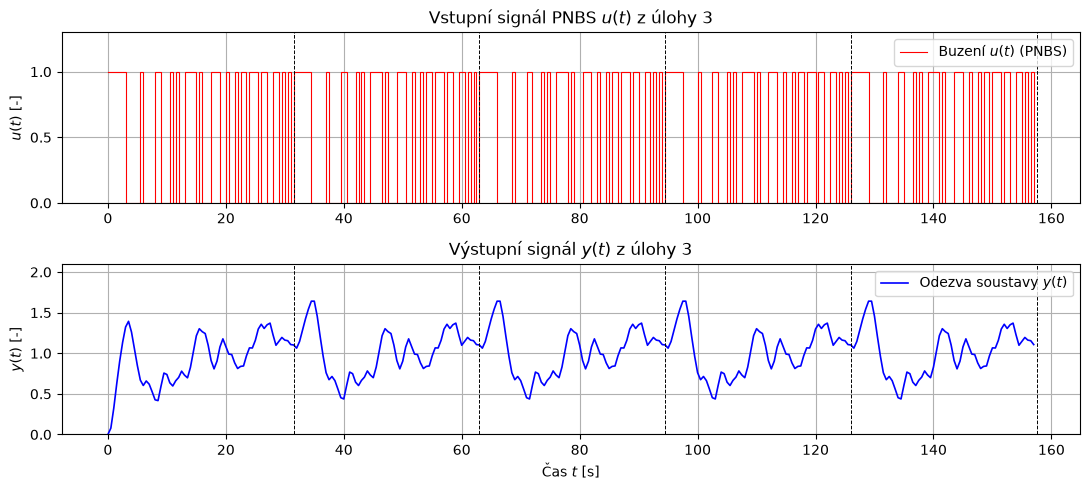

In [2]:
data = np.loadtxt('data_pnbs.csv', delimiter=',', skiprows=1)
u_pnbs = data[:, 1]
y_pnbs = data[:, 2]

N_pnbs = len(u_pnbs)
N_per = 63
T0_pnbs = 0.5
t_pnbs = np.arange(N_pnbs) * T0_pnbs

print(f"Počet vzorků dat PNBS z úlohy 3: N = {N_pnbs} ({N_pnbs // N_per} period po {N_per} vzorcích)")
print(f"Perioda vzorkování: T0 = {T0_pnbs} s")

plt.figure(figsize=(11, 5))
T_G = N_per * T0_pnbs
plt.subplot(2, 1, 1)
plt.step(t_pnbs, u_pnbs, 'r-', where='post', linewidth=0.8, label=r'Buzení $u(t)$ (PNBS)')
for p in range(1, N_pnbs // N_per + 1):
    plt.axvline(p * T_G, color='k', linestyle='--', linewidth=0.7)
plt.ylabel(r'$u(t)$ [-]')
plt.ylim(0.0, 1.3)
plt.yticks([0.0, 0.5, 1.0])
plt.title(r'Vstupní signál PNBS $u(t)$ z úlohy 3')
plt.grid(True)
plt.legend(loc='upper right')

plt.subplot(2, 1, 2)
plt.plot(t_pnbs, y_pnbs, 'b-', linewidth=1.2, label=r'Odezva soustavy $y(t)$')
for p in range(1, N_pnbs // N_per + 1):
    plt.axvline(p * T_G, color='k', linestyle='--', linewidth=0.7)
plt.xlabel(r'Čas $t$ [s]')
plt.ylabel(r'$y(t)$ [-]')
plt.ylim(0.0, 2.1)
plt.title(r'Výstupní signál $y(t)$ z úlohy 3')
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig("data_pnbs.png", dpi=300)
plt.show()


## Analytické modely soustav (Control System Toolbox)


In [3]:
num_rnd = [1.0]
den_rnd = [0.16, 2.4, 1.0]
num_pnbs = [2.0]
den_pnbs = np.polymul(np.polymul([2.0, 1.0], [0.5, 1.0]), [0.25, 1.0])

b_rnd, a_rnd, _ = signal.cont2discrete((num_rnd, den_rnd), T0_rnd, method='zoh')
b_pnbs, a_pnbs, _ = signal.cont2discrete((num_pnbs, den_pnbs), T0_pnbs, method='zoh')
y_model_rnd = signal.lfilter(b_rnd.flatten(), a_rnd, u_rnd)
y_model_pnbs = signal.lfilter(b_pnbs.flatten(), a_pnbs, u_pnbs)

T_i = np.sort(-1 / np.roots(den_rnd).real)[::-1]
t_fine = np.linspace(0, 60, 6001)
s_fine = signal.step((num_rnd, den_rnd), T=t_fine)[1]
t_ust = t_fine[np.where(np.abs(s_fine - 1) > 0.02)[0][-1] + 1]

print(f"Soustava z úlohy 1: časové konstanty {T_i[0]:.3f} s a {T_i[1]:.3f} s, statické zesílení K = 1")
print(f"Doba přechodového děje (ustálení na 2 %): {t_ust:.2f} s, tj. cca {np.ceil(t_ust / T0_rnd):.0f} vzorků při T0 = {T0_rnd:.1f} s")
print("Soustava z úlohy 3: časové konstanty 2 s, 0.5 s a 0.25 s, statické zesílení K = 2")
print(f"Max. rozdíl uložené odezvy a odezvy modelu: náhodný signál {np.max(np.abs(y_rnd - y_model_rnd)):.2e}, PNBS {np.max(np.abs(y_pnbs - y_model_pnbs)):.2e}")


Soustava z úlohy 1: časové konstanty 2.331 s a 0.069 s, statické zesílení K = 1
Doba přechodového děje (ustálení na 2 %): 9.20 s, tj. cca 10 vzorků při T0 = 1.0 s
Soustava z úlohy 3: časové konstanty 2 s, 0.5 s a 0.25 s, statické zesílení K = 2
Max. rozdíl uložené odezvy a odezvy modelu: náhodný signál 5.28e-05, PNBS 4.96e-09


## Výpočet autokorelačních a vzájemných korelačních funkcí


Maximální posunutí m = int(0.1 N): náhodný signál m = 25, PNBS m = 31
PNBS je periodický signál: použita poslední (ustálená) perioda, N = 63 vzorků, s periodickým prodloužením

Hodnoty korelačních funkcí (náhodný signál):


,R_uu(i),R_yy(i),R_uy(i)
i,,,
0,1.00771,0.17166,-0.04171
1,-0.03479,0.10413,0.30524
2,-0.03771,0.05175,0.20805
3,-0.10863,0.01696,0.12178
4,0.03525,0.00348,0.04267
5,-0.06964,-0.01325,0.03666
6,-0.16580,-0.02034,0.00309
8,0.07426,0.00223,-0.01542
10,-0.10870,-0.00695,0.00164



Hodnoty korelačních funkcí (PNBS):


,R_uu(i),R_yy(i),R_uy(i)
i,,,
0,0.50794,1.11241,0.50794
1,0.25397,1.10652,0.52784
2,0.25397,1.09327,0.57102
3,0.25397,1.07880,0.58396
4,0.25397,1.06588,0.57831
5,0.25397,1.05518,0.56702
6,0.25397,1.04663,0.55555
8,0.25397,1.03458,0.53749
10,0.25397,1.02723,0.52596


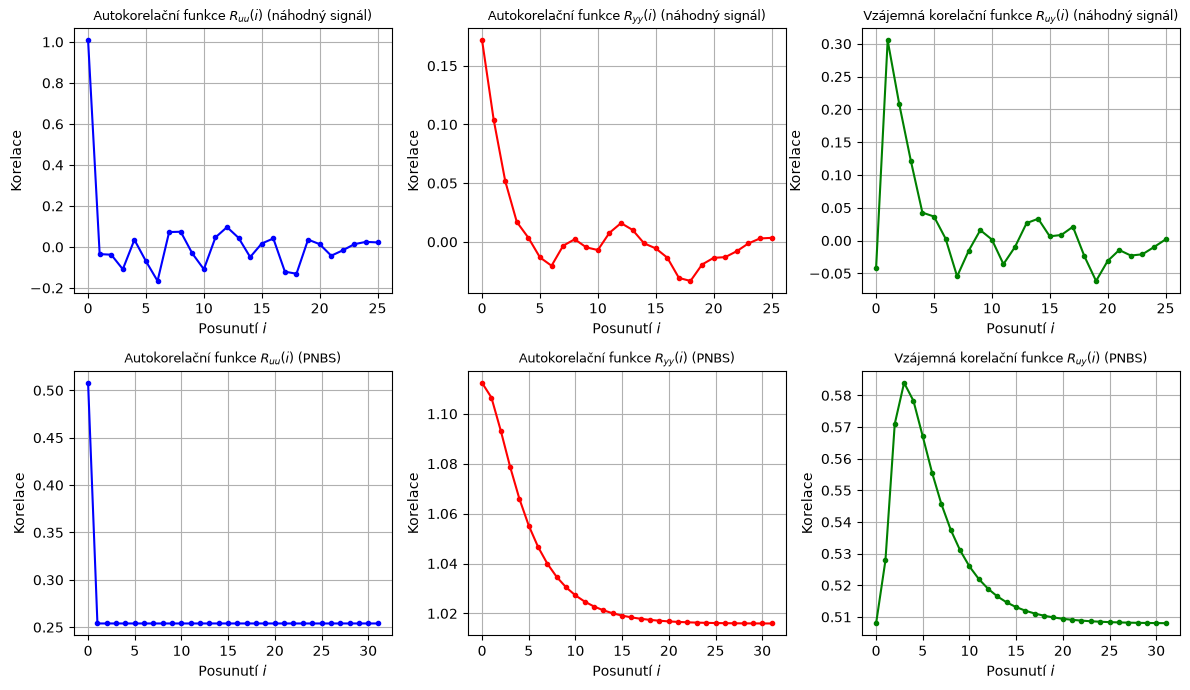

In [4]:
m_rnd = int(0.1 * N_rnd)
m_pnbs = int(0.1 * N_pnbs)

def korelace(u, y, m, periodicky=False):
    N = len(u)
    R_uu = np.zeros(m + 1)
    R_yy = np.zeros(m + 1)
    R_uy = np.zeros(m + 1)
    for i in range(m + 1):
        if periodicky:
            norm = N
            u_i, y_i = np.roll(u, -i), np.roll(y, -i)
            u_k, y_k = u, y
        else:
            norm = N - i
            u_i, y_i = u[i:], y[i:]
            u_k, y_k = u[:norm], y[:norm]
        R_uu[i] = np.sum(u_k * u_i[:norm]) / norm
        R_yy[i] = np.sum(y_k * y_i[:norm]) / norm
        R_uy[i] = np.sum(u_k * y_i[:norm]) / norm
    return R_uu, R_yy, R_uy

R_uu_rnd, R_yy_rnd, R_uy_rnd = korelace(u_rnd, y_rnd, m_rnd)
R_uu_pnbs, R_yy_pnbs, R_uy_pnbs = korelace(u_pnbs[-N_per:], y_pnbs[-N_per:], m_pnbs, periodicky=True)

idx = [0, 1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 25]

print(f"Maximální posunutí m = int(0.1 N): náhodný signál m = {m_rnd}, PNBS m = {m_pnbs}")
print(f"PNBS je periodický signál: použita poslední (ustálená) perioda, N = {N_per} vzorků, s periodickým prodloužením")
for nazev, R_uu, R_yy, R_uy in (('náhodný signál', R_uu_rnd, R_yy_rnd, R_uy_rnd), ('PNBS', R_uu_pnbs, R_yy_pnbs, R_uy_pnbs)):
    print(f"\nHodnoty korelačních funkcí ({nazev}):")
    display(pd.DataFrame({
        'R_uu(i)': [f"{R_uu[i]:.5f}" for i in idx],
        'R_yy(i)': [f"{R_yy[i]:.5f}" for i in idx],
        'R_uy(i)': [f"{R_uy[i]:.5f}" for i in idx]
    }, index=pd.Index(idx, name='i')))

fig, osy = plt.subplots(2, 3, figsize=(12, 7))
for r, (R_uu, R_yy, R_uy, m, nazev) in enumerate((
        (R_uu_rnd, R_yy_rnd, R_uy_rnd, m_rnd, 'náhodný signál'),
        (R_uu_pnbs, R_yy_pnbs, R_uy_pnbs, m_pnbs, 'PNBS'))):
    i_vals = np.arange(0, m + 1)
    osy[r, 0].plot(i_vals, R_uu, 'b.-')
    osy[r, 0].set_title(rf'Autokorelační funkce $R_{{uu}}(i)$ ({nazev})', fontsize=9)
    osy[r, 1].plot(i_vals, R_yy, 'r.-')
    osy[r, 1].set_title(rf'Autokorelační funkce $R_{{yy}}(i)$ ({nazev})', fontsize=9)
    osy[r, 2].plot(i_vals, R_uy, 'g.-')
    osy[r, 2].set_title(rf'Vzájemná korelační funkce $R_{{uy}}(i)$ ({nazev})', fontsize=9)
    for a in osy[r]:
        a.set_xlabel(r'Posunutí $i$')
        a.set_ylabel('Korelace')
        a.grid(True)
plt.tight_layout()
plt.savefig("korelace.png", dpi=300)
plt.show()


## Výpočet impulsní funkce korelační analýzou


Hodnoty impulsní funkce (čas t = i·T0, kde T0 = 1 s u náhodného signálu a T0 = 0.5 s u PNBS):


,g(i) analyticky (náhodný),g(i) odhad (náhodný),g(i) analyticky (PNBS),g(i) odhad (PNBS)
i,,,,
0,0.00000,0.00143,0.00000,0.00008
1,0.32904,0.33176,0.15670,0.15678
2,0.23403,0.23646,0.49678,0.49686
3,0.15240,0.15398,0.59868,0.59876
4,0.09924,0.10023,0.55417,0.55425
5,0.06463,0.06450,0.46529,0.46537
6,0.04209,0.04383,0.37495,0.37503
8,0.01785,0.01754,0.23276,0.23284
10,0.00757,0.00735,0.14190,0.14198


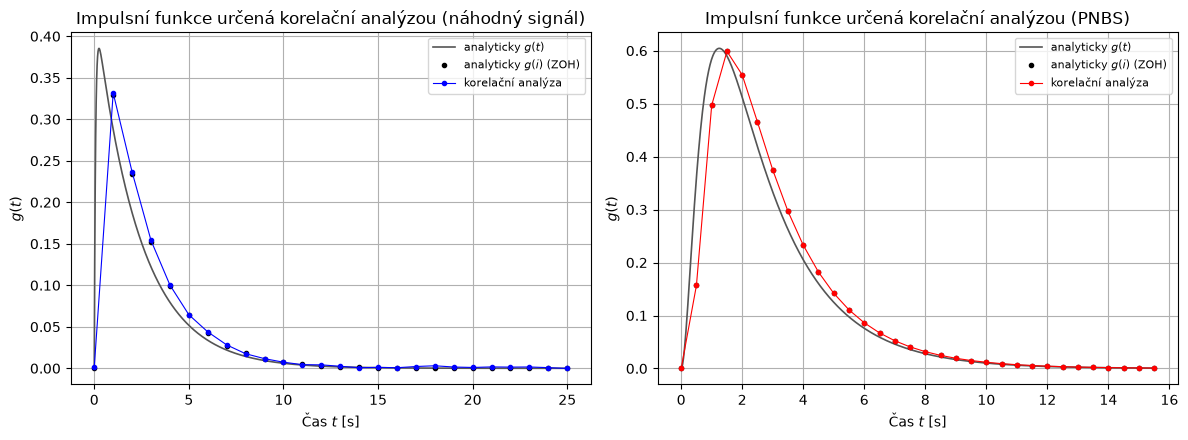

In [5]:
def wiener_hopf(R_uu, R_uy, T0):
    R = linalg.toeplitz(R_uu)
    r = R_uy / T0
    return linalg.solve(R, r)

g_rnd = wiener_hopf(R_uu_rnd, R_uy_rnd, T0_rnd)
g_pnbs = wiener_hopf(R_uu_pnbs, R_uy_pnbs, T0_pnbs)

t_rnd_i = np.arange(m_rnd + 1) * T0_rnd
t_pnbs_i = np.arange(m_pnbs + 1) * T0_pnbs
t_c_rnd = np.linspace(0, m_rnd * T0_rnd, 1000)
t_c_pnbs = np.linspace(0, m_pnbs * T0_pnbs, 1000)
g_spoj_rnd = signal.impulse((num_rnd, den_rnd), T=t_c_rnd)[1]
g_spoj_pnbs = signal.impulse((num_pnbs, den_pnbs), T=t_c_pnbs)[1]
s_spoj_rnd = signal.step((num_rnd, den_rnd), T=t_c_rnd)[1]
s_spoj_pnbs = signal.step((num_pnbs, den_pnbs), T=t_c_pnbs)[1]
s_ref_rnd = signal.step((num_rnd, den_rnd), T=t_rnd_i)[1]
s_ref_pnbs = signal.step((num_pnbs, den_pnbs), T=t_pnbs_i)[1]
g_ref_rnd = np.r_[0.0, np.diff(s_ref_rnd)] / T0_rnd
g_ref_pnbs = np.r_[0.0, np.diff(s_ref_pnbs)] / T0_pnbs

print("Hodnoty impulsní funkce (čas t = i·T0, kde T0 = 1 s u náhodného signálu a T0 = 0.5 s u PNBS):")
display(pd.DataFrame({
    'g(i) analyticky (náhodný)': [f"{g_ref_rnd[i]:.5f}" for i in idx],
    'g(i) odhad (náhodný)': [f"{g_rnd[i]:.5f}" for i in idx],
    'g(i) analyticky (PNBS)': [f"{g_ref_pnbs[i]:.5f}" for i in idx],
    'g(i) odhad (PNBS)': [f"{g_pnbs[i]:.5f}" for i in idx]
}, index=pd.Index(idx, name='i')))

fig, osy = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (t_c, g_spoj, t_i, g_ref, g_est, bar, nazev) in zip(osy, (
        (t_c_rnd, g_spoj_rnd, t_rnd_i, g_ref_rnd, g_rnd, 'b', 'náhodný signál'),
        (t_c_pnbs, g_spoj_pnbs, t_pnbs_i, g_ref_pnbs, g_pnbs, 'r', 'PNBS'))):
    a.plot(t_c, g_spoj, color='#555555', linewidth=1.2, label=r'analyticky $g(t)$')
    a.plot(t_i, g_ref, 'k.', markersize=6, label=r'analyticky $g(i)$ (ZOH)')
    a.plot(t_i, g_est, bar + '.-', linewidth=0.8, label='korelační analýza')
    a.set_title(rf'Impulsní funkce určená korelační analýzou ({nazev})')
    a.set_xlabel(r'Čas $t$ [s]')
    a.set_ylabel(r'$g(t)$')
    a.grid(True)
    a.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig("impulsni_funkce.png", dpi=300)
plt.show()


## Výpočet přechodové funkce z impulsní funkce


Ustálená hodnota přechodové funkce: náhodný signál 1.02329 (teoreticky 1), PNBS 1.99996 (teoreticky 2)

Hodnoty přechodové funkce:


,s(i) analyticky (náhodný),s(i) odhad (náhodný),s(i) analyticky (PNBS),s(i) odhad (PNBS)
i,,,,
0,0.00000,0.00143,0.00000,0.00004
1,0.32904,0.33319,0.07835,0.07843
2,0.56307,0.56965,0.32674,0.32686
3,0.71547,0.72362,0.62608,0.62624
4,0.81471,0.82385,0.90317,0.90337
5,0.87934,0.88835,1.13581,1.13605
6,0.92143,0.93218,1.32329,1.32357
8,0.96668,0.97790,1.58800,1.58836
10,0.98587,0.99685,1.74990,1.75033


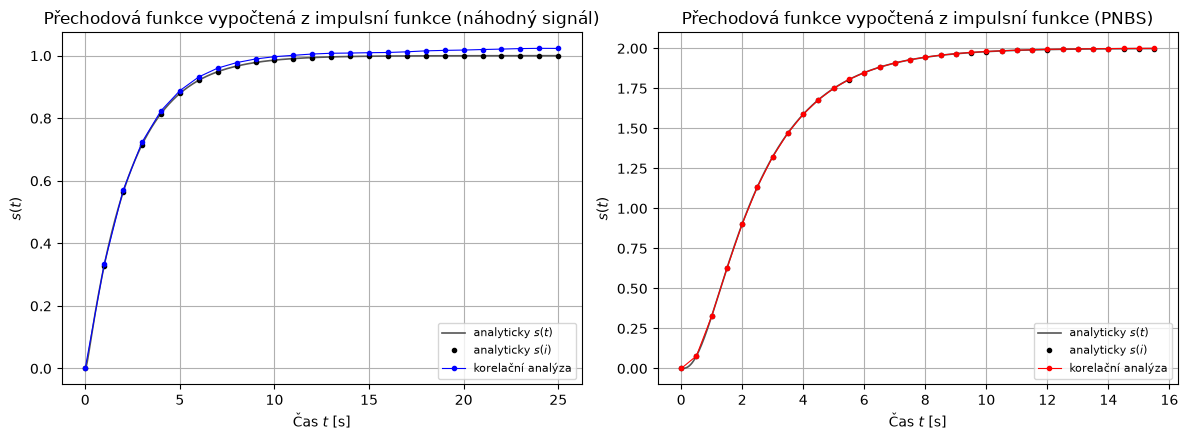

In [6]:
s_rnd = T0_rnd * np.cumsum(g_rnd)
s_pnbs = T0_pnbs * np.cumsum(g_pnbs)

print(f"Ustálená hodnota přechodové funkce: náhodný signál {s_rnd[-1]:.5f} (teoreticky 1), PNBS {s_pnbs[-1]:.5f} (teoreticky 2)")
print("\nHodnoty přechodové funkce:")
display(pd.DataFrame({
    's(i) analyticky (náhodný)': [f"{s_ref_rnd[i]:.5f}" for i in idx],
    's(i) odhad (náhodný)': [f"{s_rnd[i]:.5f}" for i in idx],
    's(i) analyticky (PNBS)': [f"{s_ref_pnbs[i]:.5f}" for i in idx],
    's(i) odhad (PNBS)': [f"{s_pnbs[i]:.5f}" for i in idx]
}, index=pd.Index(idx, name='i')))

fig, osy = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (t_c, s_spoj, t_i, s_ref, s_est, bar, nazev) in zip(osy, (
        (t_c_rnd, s_spoj_rnd, t_rnd_i, s_ref_rnd, s_rnd, 'b', 'náhodný signál'),
        (t_c_pnbs, s_spoj_pnbs, t_pnbs_i, s_ref_pnbs, s_pnbs, 'r', 'PNBS'))):
    a.plot(t_c, s_spoj, color='#555555', linewidth=1.2, label=r'analyticky $s(t)$')
    a.plot(t_i, s_ref, 'k.', markersize=6, label=r'analyticky $s(i)$')
    a.plot(t_i, s_est, bar + '.-', linewidth=0.8, label='korelační analýza')
    a.set_title(rf'Přechodová funkce vypočtená z impulsní funkce ({nazev})')
    a.set_xlabel(r'Čas $t$ [s]')
    a.set_ylabel(r'$s(t)$')
    a.grid(True)
    a.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig("prechodova_funkce.png", dpi=300)
plt.show()


## Porovnání s odhady modelů ARX a FIR (System Identification Toolbox)


Model ARX: řád 2 pro náhodný signál, řád 3 pro PNBS (metoda nejmenších čtverců)

Hodnoty přechodové funkce (náhodný signál):


,s(i) analyticky,korelační analýza,ARX,FIR
i,,,,
1,0.32904,0.33319,0.32905,0.32905
2,0.56307,0.56965,0.56307,0.56307
3,0.71547,0.72362,0.71547,0.71547
4,0.81471,0.82385,0.81471,0.81471
5,0.87934,0.88835,0.87934,0.87934
6,0.92143,0.93218,0.92142,0.92142
8,0.96668,0.97790,0.96668,0.96667
10,0.98587,0.99685,0.98587,0.98586
15,0.99835,1.00960,0.99834,0.99834



Hodnoty přechodové funkce (PNBS):


,s(i) analyticky,korelační analýza,ARX,FIR
i,,,,
1,0.07835,0.07843,0.07835,0.07843
2,0.32674,0.32686,0.32674,0.32685
3,0.62608,0.62624,0.62608,0.62623
4,0.90317,0.90337,0.90317,0.90334
5,1.13581,1.13605,1.13581,1.13602
6,1.32329,1.32357,1.32329,1.32353
8,1.58800,1.58836,1.58800,1.58834
10,1.74990,1.75033,1.74990,1.75034
15,1.92833,1.92896,1.92833,1.92899


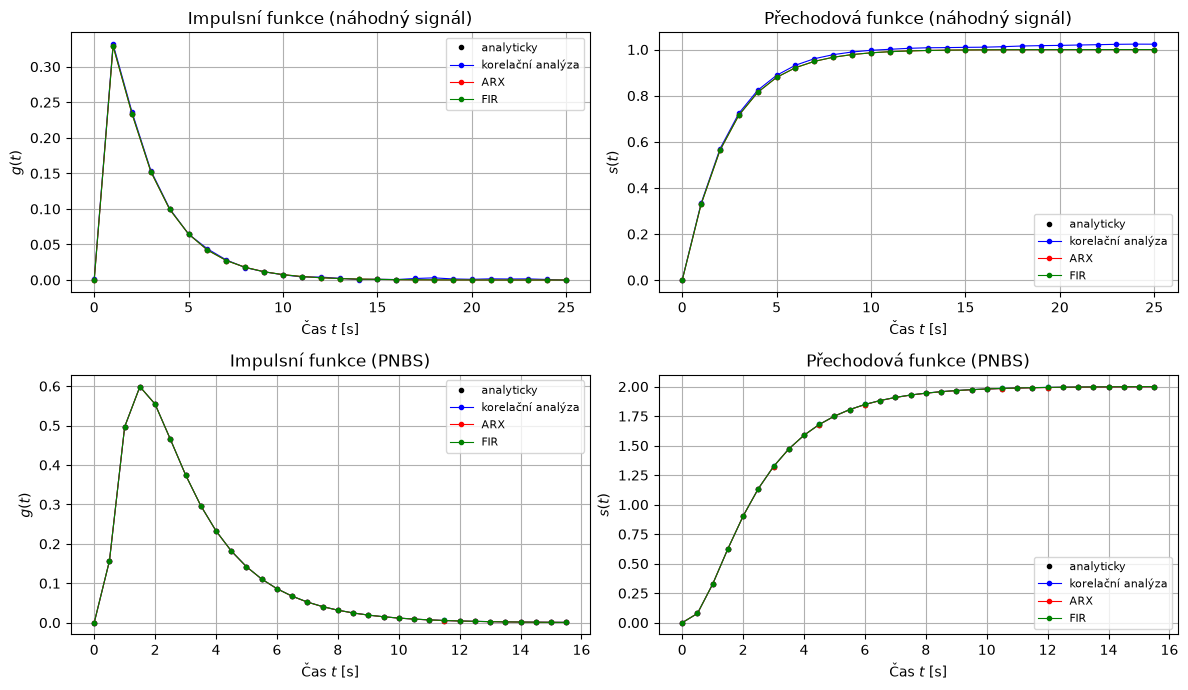

In [7]:
def fir_odhad(u, y, m):
    k = np.arange(m, len(u))
    X = np.column_stack([u[k - j] for j in range(m + 1)])
    return np.linalg.lstsq(X, y[k], rcond=None)[0]

def arx_odhad(u, y, n):
    k = np.arange(n, len(u))
    X = np.column_stack([-y[k - j] for j in range(1, n + 1)] + [u[k - j] for j in range(1, n + 1)])
    th = np.linalg.lstsq(X, y[k], rcond=None)[0]
    return np.r_[1.0, th[:n]], np.r_[0.0, th[n:]]

def vahy(B, A, m):
    delta = np.zeros(m + 1)
    delta[0] = 1.0
    return signal.lfilter(B, A, delta)

h_fir_rnd = fir_odhad(u_rnd, y_rnd, m_rnd)
h_fir_pnbs = fir_odhad(u_pnbs, y_pnbs, m_pnbs)
A_rnd, B_rnd = arx_odhad(u_rnd, y_rnd, 2)
A_pnbs, B_pnbs = arx_odhad(u_pnbs, y_pnbs, 3)
h_arx_rnd = vahy(B_rnd, A_rnd, m_rnd)
h_arx_pnbs = vahy(B_pnbs, A_pnbs, m_pnbs)

g_fir_rnd, g_fir_pnbs = h_fir_rnd / T0_rnd, h_fir_pnbs / T0_pnbs
g_arx_rnd, g_arx_pnbs = h_arx_rnd / T0_rnd, h_arx_pnbs / T0_pnbs
s_fir_rnd, s_fir_pnbs = np.cumsum(h_fir_rnd), np.cumsum(h_fir_pnbs)
s_arx_rnd, s_arx_pnbs = np.cumsum(h_arx_rnd), np.cumsum(h_arx_pnbs)

print("Model ARX: řád 2 pro náhodný signál, řád 3 pro PNBS (metoda nejmenších čtverců)")
for nazev, s_ref, s_kor, s_arx, s_fir in (
        ('náhodný signál', s_ref_rnd, s_rnd, s_arx_rnd, s_fir_rnd),
        ('PNBS', s_ref_pnbs, s_pnbs, s_arx_pnbs, s_fir_pnbs)):
    print(f"\nHodnoty přechodové funkce ({nazev}):")
    display(pd.DataFrame({
        's(i) analyticky': [f"{s_ref[i]:.5f}" for i in idx[1:]],
        'korelační analýza': [f"{s_kor[i]:.5f}" for i in idx[1:]],
        'ARX': [f"{s_arx[i]:.5f}" for i in idx[1:]],
        'FIR': [f"{s_fir[i]:.5f}" for i in idx[1:]]
    }, index=pd.Index(idx[1:], name='i')))

fig, osy = plt.subplots(2, 2, figsize=(12, 7))
for r, (t_i, g_ref, g_kor, g_arx, g_fir, s_ref, s_kor, s_arx, s_fir, nazev) in enumerate((
        (t_rnd_i, g_ref_rnd, g_rnd, g_arx_rnd, g_fir_rnd, s_ref_rnd, s_rnd, s_arx_rnd, s_fir_rnd, 'náhodný signál'),
        (t_pnbs_i, g_ref_pnbs, g_pnbs, g_arx_pnbs, g_fir_pnbs, s_ref_pnbs, s_pnbs, s_arx_pnbs, s_fir_pnbs, 'PNBS'))):
    osy[r, 0].plot(t_i, g_ref, 'k.', markersize=6, label='analyticky')
    osy[r, 0].plot(t_i, g_kor, 'b.-', linewidth=0.8, label='korelační analýza')
    osy[r, 0].plot(t_i, g_arx, 'r.-', linewidth=0.8, label='ARX')
    osy[r, 0].plot(t_i, g_fir, 'g.-', linewidth=0.8, label='FIR')
    osy[r, 0].set_title(rf'Impulsní funkce ({nazev})')
    osy[r, 0].set_ylabel(r'$g(t)$')
    osy[r, 1].plot(t_i, s_ref, 'k.', markersize=6, label='analyticky')
    osy[r, 1].plot(t_i, s_kor, 'b.-', linewidth=0.8, label='korelační analýza')
    osy[r, 1].plot(t_i, s_arx, 'r.-', linewidth=0.8, label='ARX')
    osy[r, 1].plot(t_i, s_fir, 'g.-', linewidth=0.8, label='FIR')
    osy[r, 1].set_title(rf'Přechodová funkce ({nazev})')
    osy[r, 1].set_ylabel(r'$s(t)$')
    for a in osy[r]:
        a.set_xlabel(r'Čas $t$ [s]')
        a.grid(True)
        a.legend(loc='best', fontsize=8)
plt.tight_layout()
plt.savefig("porovnani_toolbox.png", dpi=300)
plt.show()


## Vyhodnocení odchylek od analytických průběhů


In [8]:
metody = [
    ('korelační analýza', 'náhodný signál', g_rnd, s_rnd, g_ref_rnd, s_ref_rnd),
    ('ARX', 'náhodný signál', g_arx_rnd, s_arx_rnd, g_ref_rnd, s_ref_rnd),
    ('FIR', 'náhodný signál', g_fir_rnd, s_fir_rnd, g_ref_rnd, s_ref_rnd),
    ('korelační analýza', 'PNBS', g_pnbs, s_pnbs, g_ref_pnbs, s_ref_pnbs),
    ('ARX', 'PNBS', g_arx_pnbs, s_arx_pnbs, g_ref_pnbs, s_ref_pnbs),
    ('FIR', 'PNBS', g_fir_pnbs, s_fir_pnbs, g_ref_pnbs, s_ref_pnbs)]

radky = []
for metoda, data_s, g_est, s_est, g_ref, s_ref in metody:
    radky.append([metoda, data_s,
                  f"{np.max(np.abs(g_est - g_ref)):.5f}", f"{np.max(np.abs(s_est - s_ref)):.5f}"])

print("Maximální odchylky od analytických hodnot (i = 0, ..., m):")
display(pd.DataFrame(radky, columns=['Metoda', 'Data', 'max |Δg|', 'max |Δs|']))


Maximální odchylky od analytických hodnot (i = 0, ..., m):


,Metoda,Data,max |Δg|,max |Δs|
0,korelační analýza,náhodný signál,0.00280,0.02356
1,ARX,náhodný signál,0.00000,0.00000
2,FIR,náhodný signál,0.00000,0.00002
3,korelační analýza,PNBS,0.00008,0.00127
4,ARX,PNBS,0.00000,0.00000
5,FIR,PNBS,0.00011,0.00125


## Závěr

V této úloze jsem se zabýval určením impulsní a přechodové funkce lineární soustavy pomocí korelační analýzy ze dvou souborů vstupně-výstupních dat a jejich porovnáním s identifikací a s analytickými průběhy.

### Postup řešení a vlastní data:
1. **Data:** Jako první soubor jsem použil náhodný signál z úlohy 1 ($N = 251$ vzorků, soubory `u.csv` a `y.csv`, $T_0 = 1$ s), jako druhý data z úlohy 3 získaná buzením soustavy generátorem PNBS (soubor `data_pnbs.csv`, $315$ vzorků, $T_0 = 0{,}5$ s). Analytické modely soustav jsou $G_S(s) = \frac{1}{0{,}16s^2 + 2{,}4s + 1}$ (úloha 1) a $G_S(s) = \frac{2}{(2s+1)(0{,}5s+1)(0{,}25s+1)}$ (úloha 3).
2. **Korelační funkce:** Pro obě data jsem vypočítal autokorelační funkce $R_{uu}(i)$, $R_{yy}(i)$ a vzájemnou korelační funkci $R_{uy}(i)$ pro $i = 0, \dots, m$, kde $m = \mathrm{int}(0{,}1\,N)$ ($m = 25$ a $m = 31$). U PNBS jsem použil poslední (ustálenou) periodu s periodickým prodloužením signálu.
3. **Impulsní a přechodová funkce:** Impulsní funkci jsem získal řešením soustavy rovnic $\mathbf{R}\,\mathbf{g} = \mathbf{r}$ (Wienerova–Hopfova rovnice), kde vzájemnou korelační funkci dělím periodou vzorkování $T_0$. Přechodovou funkci jsem vypočítal součtem hodnot impulsní funkce. Výsledky jsem porovnal s odhady modelů ARX a FIR (náhrada System Identification Toolboxu) a s analytickými průběhy (náhrada Control System Toolboxu, `scipy.signal`).

### Shrnutí výsledků:
- **Korelační funkce:** Autokorelační funkce vstupu má pík v počátku ($R_{uu}(0) = 1{,}00771$ u náhodného signálu, $0{,}50794$ u PNBS) a jinde kolísá kolem nuly (náhodný signál, konečná délka záznamu) nebo je konstantní $0{,}254$, tedy druhá mocnina střední hodnoty $0{,}5$ (PNBS). Vstup se tedy chová jako bílý šum. Výsledky odpovídají teorii: u PNBS se $R_{uu}$, $R_{uy}$ a $R_{yy}$ shodují s teoretickými hodnotami s přesností $10^{-9}$. Vzájemná korelační funkce $R_{uy}(i)$ má maximum pro $i = 1$ ($0{,}30524$) u náhodného signálu a pro $i = 3$ ($0{,}58396$) u PNBS a pak klesá k nule.
- **Impulsní funkce:** Hodnoty určené korelační analýzou se shodují s analytickými, například $\hat g(1) = 0{,}33176$ při analytické hodnotě $0{,}32904$ (náhodný signál) a $\hat g(1) = 0{,}15678$ při $0{,}15670$ (PNBS). Maximální odchylka je $0{,}00280$ u náhodného signálu a $0{,}00008$ u PNBS. Odhad odpovídá hodnotám ZOH modelu (střední hodnota $g(t)$ přes interval $T_0$), proto neleží přesně na spojité křivce $g(t)$.
- **Přechodová funkce:** Ze součtu impulsní funkce se ustálí na hodnotě $1{,}02329$ a $1{,}99996$ (teoreticky $1$ a $2$), maximální odchylka činí $0{,}02356$ a $0{,}00127$. Odchylky se sčítají, proto jsou větší než u impulsní funkce.
- **Přesnost:** Přesnější jsou data získaná buzením PNBS (odchylka impulsní funkce $0{,}00008$ proti $0{,}00280$, přechodové funkce $0{,}00127$ proti $0{,}02356$), což odpovídá teorii: PNBS je periodický signál s téměř rovnoměrným spektrem, zatímco náhodný signál je jen jedna realizace šumu s konečnou délkou.
- **Srovnání s identifikací:** Modely ARX a FIR odhadnuté z dat (soustava startuje z klidu, proto bez odečtení středních hodnot) se shodují s analytickými průběhy téměř přesně (odchylka přechodové funkce nejvýše $0{,}00125$, u ARX prakticky nulová). Korelační analýza je méně přesná ($0{,}02356$ a $0{,}00127$), ale je jednoduchá a nevyžaduje volbu struktury modelu.
